# OCR biển số xe máy Việt Nam (ảnh crop → ký tự) — CRNN + CTC, chạy trên Raspberry Pi 4

**Vị trí trong hệ thống:** `ESP32-CAM → YOLO26 (phát hiện biển, đã train) → crop → [notebook này] → "59-P1 664.80"`.

**Vấn đề dữ liệu:** GreenParking chỉ có bbox, **không có nhãn ký tự**. Vì vậy notebook đi theo 3 giai đoạn:
1. **Train trên dữ liệu tổng hợp** (sinh biển 2 dòng đúng định dạng VN + nhiễu/mờ/chói/nghiêng) → model nền.
2. **Fine-tune bằng nhãn tay trên ảnh thật:** notebook có sẵn **179 nhãn tay** (đọc từ 179 crop GreenParking thuộc các nhóm khác nhau, nhúng ở Cell 5B) để fine-tune + đo độ chính xác thật (chia theo **biển số**, không theo nhóm, vì cùng một xe xuất hiện ở nhiều nhóm). Muốn tốt hơn: sửa tiếp `real_labels_template.csv` (chỉ gồm crop chưa có nhãn) rồi upload lại. **Nhãn giả (pseudo-label) mặc định TẮT**: lần chạy trước nó nạp nhãn sai có độ tin cậy cao (0,92–1,00) và làm lỗi 4→1, 1→7 nặng thêm.
3. **Xuất ONNX** + `plate_ocr.py` (chỉ cần `numpy + opencv + onnxruntime`, không cần PyTorch trên Pi) + `alpr_pipeline.py` (detector + OCR).

**Thiết kế model:** biển 2 dòng được cắt đôi theo chiều cao (tách ngẫu nhiên 44–56% khi train để chịu lệch), ghép 2 dòng nối ngang thành 1 ảnh 32×256, rồi CRNN (CNN + BiGRU, ~1.5 M tham số) + CTC đọc một lượt `"59P1|66480"` (`|` ngăn 2 dòng; dấu `-` và `.` được thêm lại bằng luật định dạng).

> ⚠️ Số liệu trên **dữ liệu tổng hợp không phản ánh độ chính xác thật**. Chỉ tin chỉ số trên **tập thật có nhãn tay** (Cell 7–9). Nhãn tay seed do Claude đọc bằng mắt từ ảnh — có thể sai vài chữ ở ảnh mờ; hãy rà lại nếu thấy model "sai" ở những dòng đáng ngờ.

**Bản v4 (thêm):** +73 nhãn khó (`HARD2`, đọc mù từ các crop mà v2 và v3 bất đồng hoặc 3 lần đọc lệch nhau — chủ yếu N/H/M, 7/1, 5/3, 1/T), tăng tần suất chữ N/H/M và số 3/5 trong dữ liệu giả, và **sửa lỗi dòng dưới thừa 1 chữ số** (vd `098.54` → `109854`) bằng cách bỏ ký tự có độ tin cậy thấp nhất. `TEST` (88 ảnh) vẫn giữ nguyên, không dính vào train.

**Bản v3 (thêm):** hỗ trợ **biển 2 chữ seri** (`60-FL`, `70-SA`, `86-AA`… — v2 đọc sai chắc chắn, `valid=True`), thêm **14 nhãn khó** (train) và **88 nhãn kiểm tra độc lập** (`TEST`, không dùng để train/chọn model, chỉ báo cáo ở Cell 9), có chế độ **warm-start** từ `crnn_final.pt` của bản trước để khỏi train lại 100 phút, và cờ `agree` (độ đồng thuận giữa các phiếu) để đánh dấu kết quả không chắc.

**Bản v2 sửa gì:** (1) font tổng hợp đổi sang **font condensed kiểu DIN** (Barlow/Saira Condensed — tải từ Google Fonts) thay cho DejaVu/Liberation vì hình chữ `1/4/7` khác hẳn biển thật; (2) thêm nét chữ đậm/mảnh ngẫu nhiên, tăng tỉ lệ `1/4/7` và các chữ dễ nhầm (H, N, M, K, X…); (3) tắt pseudo-label; (4) thêm bảng **nhầm lẫn ký tự** (ví dụ `4→1`) khi đánh giá; (5) OCR bỏ phiếu 3 vị trí cắt dòng ở bản ONNX.

**Chuẩn bị:** Accelerator = GPU, Internet = On, Add Data = dataset chứa `GreenParking` (giống notebook detector). Đặt `SMOKE_TEST = True` ở Cell 1 để chạy thử nhanh.

In [1]:
# =====================================================================
# CELL 0: Thư viện + seed + platform report
# =====================================================================
import os, sys, json, time, random, platform, subprocess, re, shutil, glob, importlib.util

# Cài thư viện thiếu TRƯỚC khi import numpy/torch (cài giữa chừng có thể làm lệch phiên bản -> lỗi import torch).
# Chỉ cài khi thực sự thiếu; Kaggle thường đã có sẵn onnx/onnxruntime.
_missing = [m for m in ("onnx", "onnxruntime") if importlib.util.find_spec(m) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=False)
    print("Đã cài", _missing, "- nếu sau đó import torch lỗi: Run > Restart session rồi chạy lại từ Cell 0.")

import numpy as np

SEED = 42
random.seed(SEED); np.random.seed(SEED)
T0 = time.time()

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import cv2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
torch.manual_seed(SEED)

OUT = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./work")
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(exist_ok=True)
info = {"python": sys.version.split()[0], "torch": torch.__version__, "cuda": bool(torch.cuda.is_available()),
        "cpu_count": os.cpu_count(), "seed": SEED}
if torch.cuda.is_available():
    info["gpu"] = torch.cuda.get_device_name(0)
(OUT / "platform_report.json").write_text(json.dumps(info, indent=2))
print(json.dumps(info, indent=2))

Đã cài ['onnxruntime'] - nếu sau đó import torch lỗi: Run > Restart session rồi chạy lại từ Cell 0.
{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "cuda": true,
  "cpu_count": 4,
  "seed": 42,
  "gpu": "Tesla T4"
}


In [2]:
# =====================================================================
# CELL 1: CẤU HÌNH
# =====================================================================
SMOKE_TEST = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WORKERS = min(4, os.cpu_count() or 1)

# ---- Stage 1: dữ liệu tổng hợp ----
SYN_TRAIN_N, SYN_VAL_N = 30000, 3000        # số mẫu / epoch (mỗi epoch sinh mẫu MỚI -> không lặp lại)
EPOCHS_S1, LR_S1, BATCH = 25, 2e-3, 128
# ---- Stage 2: ảnh thật (pseudo-label + nhãn tay nếu có) ----
USE_PSEUDO = False                           # TẮT: nhãn giả của model yếu làm lỗi nặng thêm (đã xảy ra ở lần chạy đầu)
PSEUDO_CONF = 0.97                           # chỉ dùng khi USE_PSEUDO=True VÀ stage 1 đạt PSEUDO_GATE trên tập thật có nhãn tay
PSEUDO_GATE = 0.80
EPOCHS_S2, LR_S2 = 20, 5e-4
# Warm-start: nếu có `crnn_final.pt` của lần train trước (upload bundle thành Kaggle Dataset) -> nạp rồi chỉ train thêm ít epoch
# trên bộ sinh mới (có biển 2 chữ seri). Đặt False để train từ đầu.
WARM_START = True
EPOCHS_S1_WARM, LR_S1_WARM = 10, 1e-3
HUMAN_WEIGHT = 1                             # hệ số lặp nhãn tay (đã được lặp tự động để bù cho tập nhỏ)
REAL_MARGIN = 0.06                           # nới bbox khi crop biển (giống lúc triển khai)
TIME_BUDGET_H = 2.5

if SMOKE_TEST:
    SYN_TRAIN_N, SYN_VAL_N, EPOCHS_S1, EPOCHS_S2, EPOCHS_S1_WARM, WORKERS = 640, 256, 1, 1, 1, 0
print(f"device={DEVICE} smoke={SMOKE_TEST}")

device=cuda smoke=False


In [3]:
# =====================================================================
# CELL 2: MODULE DÙNG CHUNG TRAIN <-> PI  (plate_ocr.py)
# Một nguồn duy nhất cho tiền xử lý + giải mã + luật định dạng -> không lệch giữa lúc train và lúc triển khai.
# =====================================================================
PLATE_OCR_PY = r'''"""plate_ocr.py - OCR biển số xe máy VN 2 dòng. Phụ thuộc: numpy, opencv, (onnxruntime khi chạy trên Pi)."""
import re
import numpy as np
import cv2

VOCAB = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ|"     # index CTC = vị trí + 1 ; 0 = blank
BLANK = 0
PLATE_W, PLATE_H = 128, 112       # crop biển được resize về cỡ này trước khi cắt dòng
LINE_W, LINE_H = 128, 32          # mỗi dòng -> 128x32 ; 2 dòng nối ngang -> 256x32
CROP_MARGIN = 0.06                # nới bbox của detector 6% mỗi phía khi crop


def make_line(img_bgr, split=0.5):
    """Crop biển (BGR/gray) -> ảnh 1 dòng 32x256 float32 đã chuẩn hoá [-1, 1]. split = vị trí cắt 2 dòng (tỉ lệ chiều cao)."""
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY) if img_bgr.ndim == 3 else img_bgr
    g = cv2.resize(g, (PLATE_W, PLATE_H), interpolation=cv2.INTER_LINEAR)
    s = int(round(PLATE_H * split))
    top = cv2.resize(g[:s], (LINE_W, LINE_H), interpolation=cv2.INTER_LINEAR)
    bot = cv2.resize(g[s:], (LINE_W, LINE_H), interpolation=cv2.INTER_LINEAR)
    line = np.concatenate([top, bot], axis=1).astype(np.float32)
    lo, hi = np.percentile(line, 1), np.percentile(line, 99)
    line = np.clip((line - lo) / max(hi - lo, 20.0), 0.0, 1.0)     # chuẩn hoá tương phản theo từng ảnh (chịu sáng/tối)
    return (line - 0.5) / 0.5


def to_input(img_bgr, split=0.5):
    return make_line(img_bgr, split)[None, None].astype(np.float32)   # (1,1,32,256)


def encode(text):
    return [VOCAB.index(c) + 1 for c in text]


def ctc_greedy(logits):
    """logits (T, C) -> (chuỗi thô, độ tin cậy trung bình của các ký tự phát ra)."""
    e = np.exp(logits - logits.max(1, keepdims=True)); p = e / e.sum(1, keepdims=True)
    idx, mx = p.argmax(1), p.max(1)
    out, confs, prev = [], [], -1
    for i, m in zip(idx, mx):
        if i != prev and i != BLANK:
            out.append(VOCAB[i - 1]); confs.append(float(m))
        prev = i
    return "".join(out), (float(np.mean(confs)) if confs else 0.0)


def ctc_decode(logits):
    """Như ctc_greedy nhưng trả thêm độ tin cậy TỪNG ký tự: (raw, conf_trung_bình, [conf_ký_tự])."""
    e = np.exp(logits - logits.max(1, keepdims=True)); p = e / e.sum(1, keepdims=True)
    idx, mx = p.argmax(1), p.max(1)
    out, confs, prev = [], [], -1
    for i, m in zip(idx, mx):
        if i != prev and i != BLANK:
            out.append(VOCAB[i - 1]); confs.append(float(m))
        prev = i
    return "".join(out), (float(np.mean(confs)) if confs else 0.0), confs


def repair_raw(raw, confs):
    """Dòng dưới (sau '|') chỉ có 4-5 chữ số: nếu model đọc dư (6+), bỏ ký tự có độ tin cậy thấp nhất cho tới khi còn 5."""
    if raw.count("|") != 1:
        return raw
    k = raw.index("|")
    top, bot, bc = raw[:k], raw[k + 1:], list(confs[k + 1:])
    if len(bc) != len(bot):
        return raw
    while len(bot) > 5:
        j = int(np.argmin(bc)); bot = bot[:j] + bot[j + 1:]; bc.pop(j)
    return top + "|" + bot


# Sửa nhầm lẫn theo VỊ TRÍ (heuristic). Dòng trên = 2 số tỉnh + (chữ+số | 2 chữ) ; dòng dưới = 4-5 chữ số.
DIGIT_FIX = {"O": "0", "Q": "0", "D": "0", "I": "1", "L": "1", "Z": "2", "S": "5", "B": "8", "G": "6", "T": "7"}
LETTER_FIX = {"0": "D", "5": "S", "2": "Z", "8": "B"}


def format_plate(raw, conf=0.0):
    res = dict(raw=raw, conf=conf, valid=False, top="", bottom="", text=raw)
    parts = raw.split("|")
    if len(parts) != 2:
        return res
    top, bot = parts
    if len(top) in (3, 4):
        t = list(top)
        for i in (0, 1):
            t[i] = DIGIT_FIX.get(t[i], t[i])
        t[2] = LETTER_FIX.get(t[2], t[2])          # ký tự thứ 4 (số HOẶC chữ, vd "A1" / "FL") được giữ nguyên
        top = "".join(t)
    bot = "".join(DIGIT_FIX.get(c, c) for c in bot)
    # dòng trên: 2 số tỉnh + (1 chữ + 1 số | 2 chữ) ; dòng dưới: 4-5 chữ số
    ok = re.fullmatch(r"\d{2}(?:[A-Z]\d|[A-Z]{2})", top) is not None and re.fullmatch(r"\d{4,5}", bot) is not None
    top_f = top[:2] + "-" + top[2:] if len(top) >= 3 else top
    bot_f = bot[:3] + "." + bot[3:] if len(bot) == 5 else bot
    res.update(valid=ok, top=top_f, bottom=bot_f, text=f"{top_f} {bot_f}")
    return res


def text_to_target(s):
    """'59-P1 664.80' | '59P1|66480' -> '59P1|66480' (None nếu không tách được 2 dòng)."""
    toks = [t for t in re.split(r"[\s|/]+", str(s).strip().upper()) if t]
    if len(toks) != 2:
        return None
    a, b = (re.sub(r"[^0-9A-Z]", "", t) for t in toks)
    return f"{a}|{b}" if a and b else None


class OnnxOCR:
    def __init__(self, path, threads=4):
        import onnxruntime as ort
        so = ort.SessionOptions(); so.intra_op_num_threads = threads
        self.sess = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
        self.inp = self.sess.get_inputs()[0].name

    def __call__(self, img_bgr, split=0.5, votes=3):
        """votes=3: đọc ở 3 vị trí cắt dòng (split-0.04, split, split+0.04) trong 1 batch rồi bỏ phiếu chuỗi thô."""
        splits = [split] if votes <= 1 else [split - 0.04, split, split + 0.04]
        x = np.concatenate([to_input(img_bgr, s) for s in splits])
        lg = self.sess.run(None, {self.inp: x})[0]
        cands = []
        for l in lg:
            raw, cf, ch = ctc_decode(l)
            cands.append((repair_raw(raw, ch), cf))
        cnt = {}
        for r, _ in cands:
            cnt[r] = cnt.get(r, 0) + 1
        top = max(cnt.values())
        best = max((c for c in cands if cnt[c[0]] == top), key=lambda c: c[1])
        res = format_plate(*best)
        res["agree"] = top / len(cands)            # 1.0 = mọi phiếu cùng kết quả
        return res
'''
(OUT / "plate_ocr.py").write_text(PLATE_OCR_PY, encoding="utf-8")
sys.path.insert(0, str(OUT))
import importlib, plate_ocr
importlib.reload(plate_ocr)
from plate_ocr import VOCAB, encode, ctc_greedy, format_plate, text_to_target, to_input
NC = len(VOCAB) + 1
print("vocab:", VOCAB, "| số lớp CTC:", NC)

vocab: 0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ| | số lớp CTC: 38


font dùng để sinh biển: ['BarlowCondensed-Medium.ttf', 'BarlowCondensed-SemiBold.ttf', 'BarlowCondensed-Bold.ttf', 'SairaCondensed-SemiBold.ttf', 'SairaCondensed-Bold.ttf']


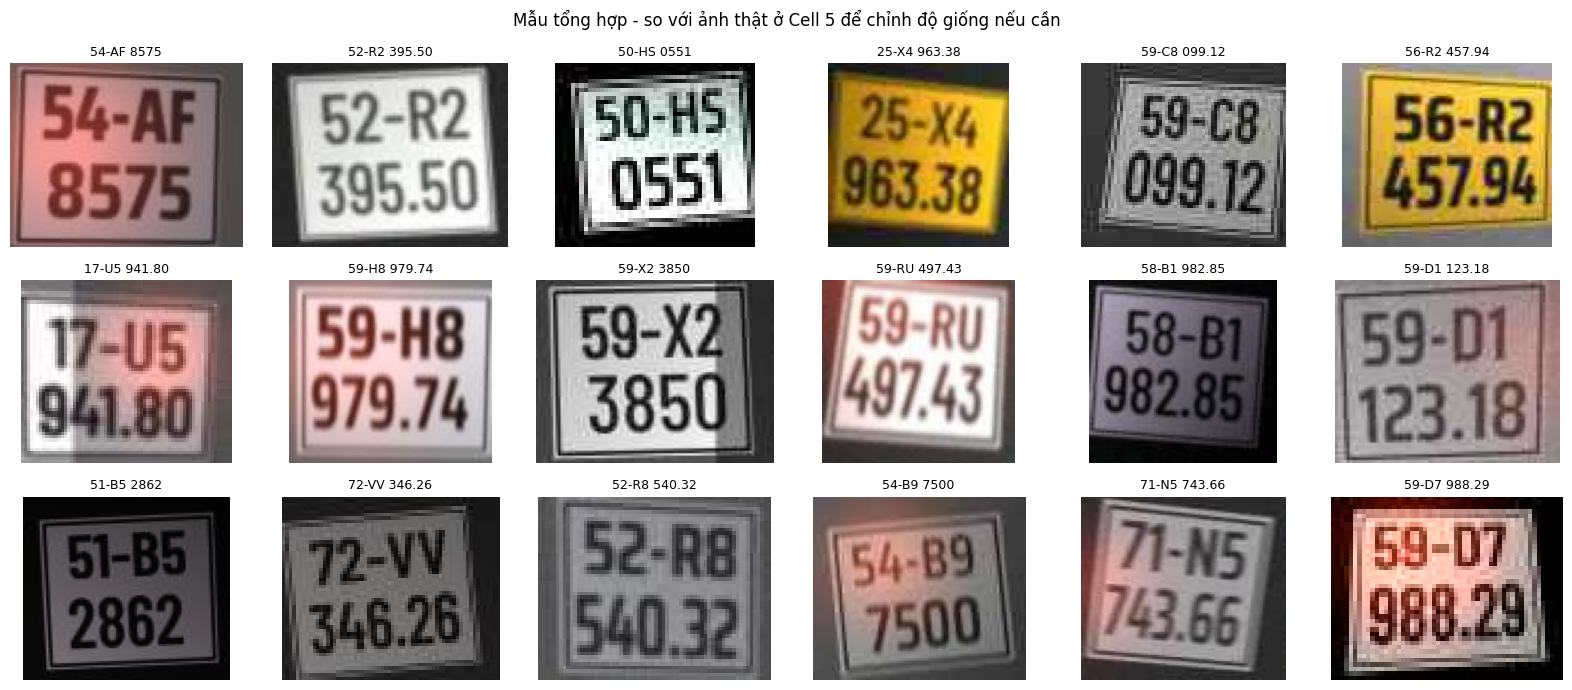

In [4]:
# =====================================================================
# CELL 3: BỘ SINH BIỂN SỐ TỔNG HỢP (biển xe máy VN 2 dòng, nền trắng/chữ đen, ~5% biển vàng)
# Mô phỏng: nghiêng/phối cảnh, crop lệch của detector, mờ/nhiễu/JPEG, độ phân giải thấp, chói đèn xe, bóng, ánh sáng yếu.
# Đã có biển 2 chữ seri (v3). TODO: chưa có seri có dấu (vd "59-MĐ1"), biển vuông ô tô, biển đỏ/xanh - thêm nếu cần.
# =====================================================================
from PIL import Image, ImageDraw, ImageFont


def find_fonts():
    fonts = []
    base = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
    fonts += [str(base / n) for n in ["DejaVuSans-Bold.ttf", "DejaVuSansMono-Bold.ttf"] if (base / n).exists()]
    pats = ["/usr/share/fonts/**/*.ttf", "/usr/share/fonts/**/*.otf", "/kaggle/input/**/*.ttf"]
    ok = ("liberation", "roboto", "notosans", "opensans", "arial", "inter-bold", "ubuntu", "dejavusans-bold")
    bad = ("italic", "oblique", "serif", "cjk", "mono", "light", "thin", "condensedlight", "symbol")
    for pat in pats:
        for f in sorted(glob.glob(pat, recursive=True)):
            n = Path(f).name.lower()
            if "bold" in n and any(k in n for k in ok) and not any(k in n for k in bad) and f not in fonts:
                fonts.append(f)
    return fonts[:10]


def fetch_condensed_fonts():
    """Biển VN dùng chữ hẹp kiểu DIN. Barlow/Saira Condensed (OFL) có hình 1/4/7/H/N gần biển thật hơn DejaVu/Liberation."""
    import urllib.request
    d = OUT / "fonts"; d.mkdir(exist_ok=True)
    base = "https://raw.githubusercontent.com/google/fonts/main/ofl/"
    items = ["barlowcondensed/BarlowCondensed-Medium.ttf", "barlowcondensed/BarlowCondensed-SemiBold.ttf",
             "barlowcondensed/BarlowCondensed-Bold.ttf", "sairacondensed/SairaCondensed-SemiBold.ttf",
             "sairacondensed/SairaCondensed-Bold.ttf"]
    got = []
    for it in items:
        dst = d / Path(it).name
        try:
            if not dst.exists():
                dst.write_bytes(urllib.request.urlopen(base + it, timeout=30).read())
            ImageFont.truetype(str(dst), 20); got.append(str(dst))
        except Exception as e:
            print("[!] không tải được", it, type(e).__name__)
    return got


FONTS = fetch_condensed_fonts()
CONDENSED = len(FONTS) >= 2
if not CONDENSED:
    print("[!!] KHÔNG tải được font condensed (cần Internet=On) -> dùng font hệ thống: dễ nhầm 1/4/7 trên biển thật!")
    FONTS = find_fonts()
SQUEEZE = (0.92, 1.08) if CONDENSED else (0.78, 1.0)
print("font dùng để sinh biển:", [Path(f).name for f in FONTS])

PROV_HOT = ["50", "51", "52", "53", "54", "55", "56", "57", "58"]
PROV_ALL = ["41", "43", "47", "48", "49", "60", "61", "62", "63", "64", "65", "66", "67", "68", "69", "70", "71", "72", "73",
            "74", "75", "76", "77", "78", "79", "80", "81", "82", "83", "84", "85", "86", "88", "89", "90", "92", "93", "94",
            "95", "97", "98", "99", "11", "12", "14", "15", "17", "18", "19", "20", "21", "22", "23", "24", "25", "26", "27",
            "28", "29", "30", "31", "32", "33", "34", "35", "36", "37", "38", "39", "40"]
SERIES = "ABCDEFGHKLMNPRSTUVXYZ"          # biển VN không dùng I, J, O, Q, W
# Tăng tần suất các ký tự hay bị nhầm để model học phân biệt: chữ H/N/M/K/X/U/V/B/D/R/P và số 1/4/7.
SERIES_P = np.array([3.0 if c in "HNM" else (2.0 if c in "KXUVBDRPT" else 1.0) for c in SERIES]); SERIES_P /= SERIES_P.sum()
DIGIT_P = np.array([1, 1.8, 1, 1.4, 1.8, 1.4, 1, 1.8, 1, 1], float); DIGIT_P /= DIGIT_P.sum()
D19_P = DIGIT_P[1:] / DIGIT_P[1:].sum()


def rand_plate(rng):
    r = rng.random()
    prov = "59" if r < 0.40 else (rng.choice(PROV_HOT) if r < 0.65 else rng.choice(PROV_ALL))
    if rng.random() < 0.18:                              # biển 2 chữ seri: 59-AA, 60-FL, 70-SA, 70-EA ...
        top = f"{prov}-{rng.choice(list(SERIES), p=SERIES_P)}{rng.choice(list(SERIES))}"
    else:
        top = f"{prov}-{rng.choice(list(SERIES), p=SERIES_P)}{rng.choice(np.arange(1, 10), p=D19_P)}"
    n = 5 if rng.random() < 0.8 else 4
    digits = "".join(str(d) for d in rng.choice(10, n, p=DIGIT_P))
    bot = f"{digits[:3]}.{digits[3:]}" if n == 5 else digits
    return top, bot


def _mask(text, font_path):
    f = ImageFont.truetype(font_path, 100)
    l, t, r, b = f.getbbox(text)
    im = Image.new("L", (r - l + 6, b - t + 6), 0)
    ImageDraw.Draw(im).text((3 - l, 3 - t), text, font=f, fill=255)
    arr = np.array(im)
    ys, xs = np.where(arr > 40)
    return arr[ys.min():ys.max() + 1, xs.min():xs.max() + 1]


CW, CH = 240, 208          # khung biển chuẩn (tỉ lệ ~1.15 như biển xe máy)


def render_clean(rng, top, bot):
    yellow = rng.random() < 0.05
    base = rng.uniform(185, 250)
    col = np.array([60, 190, 235], np.float32) * rng.uniform(0.8, 1.0) if yellow else base + rng.normal(0, 5, 3)
    plate = np.empty((CH, CW, 3), np.float32); plate[:] = col
    ink = np.full(3, rng.uniform(15, 70), np.float32)
    font = FONTS[rng.integers(len(FONTS))]
    for text, cy, hf, wmax in [(top, 0.27, 0.30, 0.74), (bot, 0.70, 0.34, 0.80)]:
        m = _mask(text, font)
        th = max(int(CH * hf * rng.uniform(0.92, 1.05)), 8)
        tw = m.shape[1] * th / m.shape[0] * rng.uniform(*SQUEEZE)
        tw = int(min(tw, wmax * CW))
        m = cv2.resize(m, (max(tw, 8), th), interpolation=cv2.INTER_AREA).astype(np.float32) / 255
        r_w = rng.random()                                   # nét chữ: mảnh / thường / đậm
        if r_w < 0.25:
            m = cv2.erode(m, np.ones((2, 2), np.uint8))
        elif r_w < 0.45:
            m = cv2.dilate(m, np.ones((2, 2), np.uint8))
        m = cv2.GaussianBlur(m, (0, 0), 0.6)
        x0 = int(CW / 2 - m.shape[1] / 2 + rng.uniform(-0.03, 0.03) * CW); y0 = int(cy * CH - th / 2 + rng.uniform(-0.02, 0.02) * CH)
        x0 = int(np.clip(x0, 0, CW - m.shape[1])); y0 = int(np.clip(y0, 0, CH - th))
        a = m[..., None]
        plate[y0:y0 + th, x0:x0 + m.shape[1]] = plate[y0:y0 + th, x0:x0 + m.shape[1]] * (1 - a) + ink * a
    i = int(rng.integers(5, 10))
    cv2.rectangle(plate, (i, i), (CW - i, CH - i), tuple(float(v) for v in ink), int(rng.integers(2, 5)))
    return plate


def place_warp_crop(plate, rng):
    pad = 70
    dark = rng.random() < 0.4
    floor = rng.uniform(15, 70) if dark else rng.uniform(80, 170)
    canvas = np.full((CH + 2 * pad, CW + 2 * pad, 3), floor, np.float32) + rng.normal(0, 4, (CH + 2 * pad, CW + 2 * pad, 1))
    canvas[pad:pad + CH, pad:pad + CW] = plate
    pc = np.float32([[pad, pad], [pad + CW, pad], [pad + CW, pad + CH], [pad, pad + CH]])
    ctr = pc.mean(0)
    ang = np.deg2rad(rng.uniform(-6, 6))
    R = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]], np.float32)
    jit = rng.uniform(0.0, 0.07) * CW
    dst = (pc - ctr) @ R.T + ctr + rng.uniform(-jit, jit, (4, 2)).astype(np.float32)
    M = cv2.getPerspectiveTransform(pc, dst.astype(np.float32))
    warped = cv2.warpPerspective(canvas, M, (canvas.shape[1], canvas.shape[0]), borderMode=cv2.BORDER_REPLICATE)
    x1, y1 = dst.min(0); x2, y2 = dst.max(0); bw, bh = x2 - x1, y2 - y1
    m = rng.uniform(-0.02, 0.10, 4)             # lệch crop của detector (âm = cắt nhẹ vào biển)
    X1, Y1 = int(max(x1 - m[0] * bw, 0)), int(max(y1 - m[1] * bh, 0))
    X2, Y2 = int(min(x2 + m[2] * bw, warped.shape[1])), int(min(y2 + m[3] * bh, warped.shape[0]))
    return warped[Y1:Y2, X1:X2]


def degrade(img, rng):
    h, w = img.shape[:2]
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    ang = rng.uniform(0, 2 * np.pi)
    g = ((xx / w - 0.5) * np.cos(ang) + (yy / h - 0.5) * np.sin(ang))
    img = img * (1 + rng.uniform(0, 0.6) * g)[..., None]
    if rng.random() < 0.30:                       # chói đèn hậu đỏ
        cx, cy = rng.uniform(0, w), rng.uniform(0, 0.5 * h); s = rng.uniform(0.15, 0.4) * w
        blob = np.exp(-((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * s * s))[..., None]
        img = img + blob * np.array([20, 40, 200], np.float32) * rng.uniform(0.3, 1.0)
    if rng.random() < 0.25:                       # bóng đổ
        x = rng.uniform(0.2, 0.8) * w; img = img * np.where(xx > x, rng.uniform(0.55, 0.9), 1.0)[..., None]
    img = img * rng.uniform(0.5, 1.15) + rng.uniform(-25, 25)
    img = 255 * np.power(np.clip(img, 0, 255) / 255, rng.uniform(0.7, 1.6))
    tw = int(rng.integers(48, 110)); th = max(int(h * tw / w), 16)
    img = cv2.resize(img.astype(np.float32), (tw, th), interpolation=cv2.INTER_AREA)
    if rng.random() < 0.6:
        img = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.3, 1.1))
    if rng.random() < 0.2:
        k = int(rng.integers(3, 6)); ker = np.zeros((k, k), np.float32); ker[k // 2, :] = 1 / k
        img = cv2.filter2D(img, -1, ker if rng.random() < 0.5 else ker.T)
    img = img + rng.normal(0, rng.uniform(0, 8), img.shape)
    img = np.clip(img, 0, 255).astype(np.uint8)
    ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(25, 90))])
    return cv2.imdecode(buf, cv2.IMREAD_COLOR)


def synth_sample(rng):
    top, bot = rand_plate(rng)
    img = degrade(place_warp_crop(render_clean(rng, top, bot), rng), rng)
    return img, re.sub(r"[^0-9A-Z]", "", top) + "|" + re.sub(r"[^0-9A-Z]", "", bot), f"{top} {bot}"


# ---- xem thử ----
rng = np.random.default_rng(0)
fig, axs = plt.subplots(3, 6, figsize=(16, 7))
for ax in axs.ravel():
    im, tgt, shown = synth_sample(rng)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(shown, fontsize=9); ax.axis("off")
plt.suptitle("Mẫu tổng hợp - so với ảnh thật ở Cell 5 để chỉnh độ giống nếu cần"); plt.tight_layout()
plt.savefig(OUT / "figures" / "synthetic_samples.png", dpi=100); plt.show()

In [5]:
# =====================================================================
# CELL 4: DATASET / MODEL / HÀM TRAIN - ĐÁNH GIÁ
# =====================================================================
class SynthDS(Dataset):
    def __init__(self, n, seed):
        self.n, self.seed, self.epoch = n, seed, 0
    def __len__(self):
        return self.n
    def __getitem__(self, i):
        rng = np.random.default_rng([self.seed, self.epoch, i])
        img, tgt, _ = synth_sample(rng)
        x = to_input(img, rng.uniform(0.44, 0.56))[0]
        return torch.from_numpy(x), tgt


def aug_real(img, rng):
    h, w = img.shape[:2]
    m = rng.uniform(0, 0.05, 4)                                       # lệch crop nhẹ
    img = img[int(m[0] * h):h - int(m[1] * h), int(m[2] * w):w - int(m[3] * w)]
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-4, 4), rng.uniform(0.95, 1.05))
    img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
    img = np.clip(img.astype(np.float32) * rng.uniform(0.7, 1.2) + rng.uniform(-20, 20), 0, 255)
    if rng.random() < 0.4:
        img = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.3, 1.0))
    return np.clip(img + rng.normal(0, rng.uniform(0, 5), img.shape), 0, 255).astype(np.uint8)


class RealDS(Dataset):
    def __init__(self, items, train=True, seed=7):
        self.items, self.train, self.seed, self.epoch = items, train, seed, 0
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, tgt = self.items[i]
        img = cv2.imread(path)
        rng = np.random.default_rng([self.seed, self.epoch, i])
        if self.train:
            img = aug_real(img, rng)
        x = to_input(img, rng.uniform(0.44, 0.56) if self.train else 0.5)[0]
        return torch.from_numpy(x), tgt


def collate(batch):
    xs = torch.stack([b[0] for b in batch])
    tg = [b[1] for b in batch]
    flat = torch.tensor([c for t in tg for c in encode(t)], dtype=torch.long)
    lens = torch.tensor([len(t) for t in tg], dtype=torch.long)
    return xs, flat, lens, tg


class CRNN(nn.Module):
    def __init__(self, nc=NC, hid=128):
        super().__init__()
        def blk(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
        self.cnn = nn.Sequential(
            blk(1, 32), nn.MaxPool2d(2, 2),                       # 16 x 128
            blk(32, 64), nn.MaxPool2d(2, 2),                      # 8 x 64
            blk(64, 128), blk(128, 128), nn.MaxPool2d((2, 1)),    # 4 x 64
            blk(128, 192), blk(192, 192), nn.MaxPool2d((2, 1)),   # 2 x 64
        )
        self.rnn = nn.GRU(192 * 2, hid, num_layers=2, bidirectional=True, batch_first=True, dropout=0.1)
        self.fc = nn.Linear(hid * 2, nc)

    def forward(self, x):                      # x: (B,1,32,256) -> (B,64,nc)
        f = self.cnn(x)                        # (B,192,2,64)
        f = f.permute(0, 3, 1, 2).flatten(2)   # (B,64,384)
        o, _ = self.rnn(f)
        return self.fc(o)


def lev(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[-1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


@torch.no_grad()
def evaluate(model, ds, batch=256):
    """exact = đúng TOÀN BỘ biển (chuỗi thô); cer = tỉ lệ lỗi ký tự."""
    model.eval()
    dl = DataLoader(ds, batch_size=batch, shuffle=False, num_workers=WORKERS, collate_fn=collate)
    n = ex = ed = tot = 0; wrong = []; conf = {}
    for xs, _, _, tg in dl:
        lg = model(xs.to(DEVICE)).float().cpu().numpy()
        for l, t in zip(lg, tg):
            p, _ = ctc_greedy(l)
            n += 1; ex += (p == t); ed += lev(p, t); tot += len(t)
            if p != t and len(wrong) < 20:
                wrong.append((t, p))
            if p != t and len(p) == len(t):                  # đếm nhầm lẫn ký tự (chỉ khi cùng độ dài)
                for a, b in zip(t, p):
                    if a != b:
                        conf[(a, b)] = conf.get((a, b), 0) + 1
    top = sorted(conf.items(), key=lambda kv: -kv[1])[:10]
    return dict(n=n, exact=ex / max(n, 1), cer=ed / max(tot, 1), wrong=wrong, confusions=[f"{a}→{b}:{c}" for (a, b), c in top])


def set_epoch(ds, ep):
    if hasattr(ds, "datasets"):
        for d in ds.datasets:
            set_epoch(d, ep)
    else:
        ds.epoch = ep


def fit(model, train_ds, val_fn, epochs, lr, tag, deadline):
    model.to(DEVICE)
    dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=WORKERS, collate_fn=collate, drop_last=True,
                    pin_memory=(DEVICE == "cuda"))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=max(epochs * len(dl), 1), pct_start=0.15)
    ctc = nn.CTCLoss(blank=0, zero_infinity=True)
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))
    best, best_state = -1.0, None
    for ep in range(epochs):
        if time.time() > deadline:
            print("[time-guard] hết quỹ thời gian -> dừng sớm"); break
        set_epoch(train_ds, ep); model.train(); tl = 0.0; t = time.time()
        for xs, flat, lens, _ in dl:
            xs = xs.to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                lg = model(xs)
            lp = lg.float().log_softmax(2).permute(1, 0, 2)
            il = torch.full((xs.size(0),), lp.size(0), dtype=torch.long)
            loss = ctc(lp, flat, il, lens)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step(); tl += loss.item()
        m = val_fn(model)
        print(f"[{tag}] ep {ep + 1:02d}/{epochs}  loss={tl / len(dl):.4f}  val exact={m['exact']:.4f} cer={m['cer']:.4f}  ({time.time() - t:.0f}s)")
        if m["exact"] >= best:
            best = m["exact"]; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best


deadline = T0 + TIME_BUDGET_H * 3600
n_par = sum(p.numel() for p in CRNN().parameters())
print(f"CRNN: {n_par / 1e6:.2f} M tham số")

CRNN: 1.50 M tham số


crop biển thật: 1748 | nhóm: 308


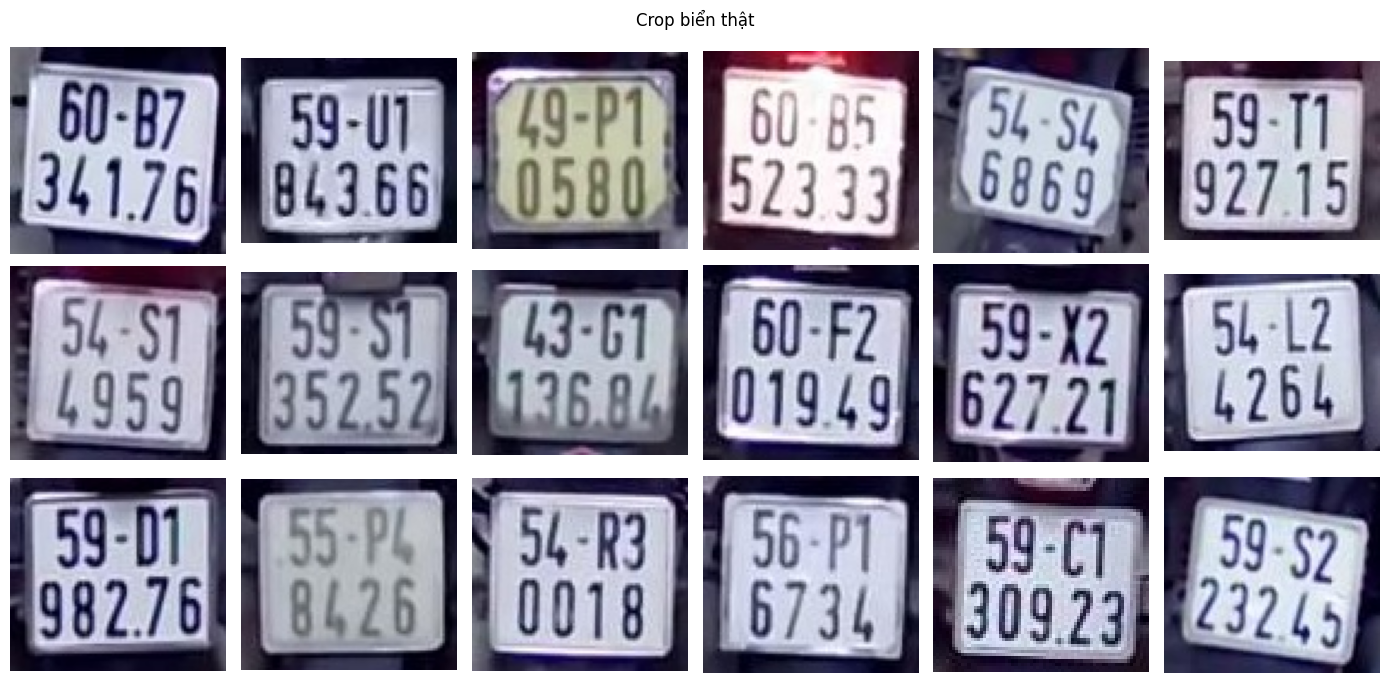

In [6]:
# =====================================================================
# CELL 5: ẢNH THẬT GreenParking -> CROP BIỂN (theo bbox location.txt) + XEM THỬ
# =====================================================================
import zipfile


def find_data_dir():
    roots = [Path(p) for p in [os.environ.get("GP_ROOT", ""), "/kaggle/input", "."] if p]
    for r in roots:
        if r.exists():
            for p in r.rglob("location.txt"):
                return p.parent
    for r in roots:
        if r.exists():
            for z in r.rglob("*.zip"):
                if "greenparking" in z.name.lower():
                    dst = OUT / "raw"; dst.mkdir(exist_ok=True)
                    zipfile.ZipFile(z).extractall(dst)
                    for p in dst.rglob("location.txt"):
                        return p.parent
    raise FileNotFoundError("Không thấy GreenParking trong /kaggle/input")


DATA_DIR = find_data_dir()
CROP_DIR = OUT / "real_crops"; CROP_DIR.mkdir(exist_ok=True)
rows = []
for ln in (DATA_DIR / "location.txt").read_text().splitlines():
    t = ln.split()
    if len(t) < 2:
        continue
    name, n = t[0], int(t[1]); nums = list(map(float, t[2:]))
    if len(nums) != 4 * n or not (DATA_DIR / name).exists():
        continue
    img = cv2.imread(str(DATA_DIR / name)); H, W = img.shape[:2]
    for k in range(n):
        x, y, w, h = nums[k * 4:(k + 1) * 4]
        if w < 8 or h < 8:
            continue                                                   # box rác (vd 1x1 px)
        mx, my = w * REAL_MARGIN, h * REAL_MARGIN
        x1, y1, x2, y2 = int(max(x - mx, 0)), int(max(y - my, 0)), int(min(x + w + mx, W)), int(min(y + h + my, H))
        out = CROP_DIR / f"{Path(name).stem}_{k}.jpg"
        cv2.imwrite(str(out), img[y1:y2, x1:x2], [cv2.IMWRITE_JPEG_QUALITY, 95])
        rows.append(dict(file=out.name, path=str(out), group=name.split("_")[0]))
REAL = pd.DataFrame(rows)
if SMOKE_TEST:
    REAL = REAL.sample(min(80, len(REAL)), random_state=SEED).reset_index(drop=True)
print(f"crop biển thật: {len(REAL)} | nhóm: {REAL.group.nunique()}")

fig, axs = plt.subplots(3, 6, figsize=(14, 7))
for ax, (_, r) in zip(axs.ravel(), REAL.sample(18, random_state=3).iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(r["path"]), cv2.COLOR_BGR2RGB)); ax.axis("off")
plt.suptitle("Crop biển thật"); plt.tight_layout(); plt.savefig(OUT / "figures" / "real_crops.png", dpi=100); plt.show()

In [7]:
# =====================================================================
# CELL 5B: NHÃN TAY SEED (179 crop GreenParking, các nhóm khác nhau) - Claude đọc bằng mắt từ ảnh crop.
# Chỉ gồm crop đọc rõ (bỏ ảnh bị chói/che/cắt mất ký tự). Có thể còn sai sót ở ảnh mờ -> hãy rà lại nếu cần.
# Bạn có thể bổ sung/ghi đè bằng CSV `real_labels*.csv` (cột file,text) trong /kaggle/input.
# =====================================================================
SEED_LABELS_CSV = """file,text
0247_04267_b_0.jpg,59-C2 443.33
0125_02237_b_0.jpg,60-Y7 3914
0320_08070_b_0.jpg,59-X1 564.19
0257_06825_b_0.jpg,54-S8 5452
0142_02093_b_0.jpg,51-H4 8354
0017_00195_b_0.jpg,59-M1 909.77
0207_04299_b_0.jpg,54-S8 5489
0129_07029_b_0.jpg,72-K5 9221
0505_04736_b_0.jpg,59-F1 599.97
0211_00866_b_0.jpg,59-C1 618.91
0515_01686_b_0.jpg,54-K4 0723
0241_05387_b_0.jpg,72-C1 709.89
0327_06891_b_0.jpg,51-K3 8796
0151_00052_b_0.jpg,59-Y1 873.04
0249_00404_b_0.jpg,59-F1 365.64
0222_04772_b_0.jpg,59-S1 554.83
0519_08151_b_0.jpg,59-C1 311.62
0256_06916_b_0.jpg,67-N1 208.86
0448_08176_b_0.jpg,52-U4 0050
0121_06062_b_0.jpg,67-B1 408.33
0155_00047_b_0.jpg,54-X4 1983
0432_05354_b_0.jpg,59-F1 750.31
0242_08139_b_0.jpg,59-L1 002.46
0147_00438_b_0.jpg,68-T9 0223
0148_02583_b_0.jpg,59-C1 131.83
0209_04563_b_0.jpg,59-F1 095.96
0200_08375_b_0.jpg,63-H3 1295
0425_07085_b_0.jpg,60-B5 523.33
0520_00060_b_0.jpg,59-P1 332.02
0339_06863_b_0.jpg,59-S1 916.67
0230_02213_b_0.jpg,70-B1 321.68
0301_08123_b_0.jpg,59-M1 944.58
0221_01394_b_0.jpg,66-L3 6400
0225_05464_b_0.jpg,36-F4 2678
0323_08009_b_0.jpg,49-B1 031.26
0316_05313_b_0.jpg,59-K1 440.76
0054_06642_b_0.jpg,84-G1 225.93
0217_00819_b_0.jpg,55-X1 7546
0131_00774_b_0.jpg,59-K1 832.35
0414_04350_b_0.jpg,59-T1 036.17
0046_06241_b_0.jpg,59-C1 653.31
0258_04132_b_0.jpg,79-K1 020.61
0415_00096_b_0.jpg,59-P2 002.63
0311_06191_b_0.jpg,59-P1 717.56
0245_06837_b_0.jpg,61-D1 128.78
0126_06297_b_0.jpg,60-C2 323.01
0137_00194_b_0.jpg,59-S1 682.87
0459_08033_b_0.jpg,59-F1 132.30
0453_06799_b_0.jpg,54-P4 8871
0428_05625_b_0.jpg,54-U3 9055
0427_07095_b_0.jpg,59-C2 414.73
0149_04597_b_0.jpg,49-K1 073.20
0236_08055_b_0.jpg,59-Y1 919.82
0307_06345_b_0.jpg,59-V2 090.48
0300_06692_b_0.jpg,71-B1 979.14
0517_05181_b_0.jpg,60-B3 220.83
0206_08036_b_0.jpg,51-U8 3423
0436_04395_b_0.jpg,59-S1 757.15
0123_06125_b_0.jpg,61-C1 064.03
0203_04832_b_0.jpg,79-U2 4621
0400_06373_b_0.jpg,79-Z1 101.84
0237_02213_b_0.jpg,70-B1 321.68
0234_02191_b_0.jpg,51-R4 2488
0136_07165_b_0.jpg,59-E1 080.58
0156_04102_b_0.jpg,54-L4 2110
0114_05537_b_0.jpg,47-K1 082.79
0154_00518_b_0.jpg,64-K4 7483
0411_04594_b_0.jpg,62-G1 097.36
0255_04769_b_0.jpg,59-L2 313.18
0407_06979_b_0.jpg,63-B3 469.05
0324_00176_b_0.jpg,54-S4 6869
0521_04268_b_0.jpg,78-N2 5941
0106_00586_b_0.jpg,59-S2 080.82
0128_08102_b_0.jpg,47-N6 9618
0338_07010_b_0.jpg,52-F5 3512
0208_04293_b_0.jpg,59-H1 528.50
0039_01689_b_0.jpg,51-R5 6273
0019_01137_b_0.jpg,59-V1 840.31
0232_07283_b_0.jpg,53-X6 6011
0059_04445_b_0.jpg,54-T1 5417
0313_05990_b_0.jpg,16-F2 6303
0315_06165_b_0.jpg,59-D2 172.44
0506_06698_b_0.jpg,51-P7 4022
0135_01754_b_0.jpg,38-Z1 0084
0354_08079_b_0.jpg,69-F2 2140
0109_02232_b_0.jpg,59-H1 193.74
0513_08387_b_0.jpg,59-L1 607.78
0143_04342_b_0.jpg,59-C1 428.18
0333_00996_b_0.jpg,59-A3 080.11
0201_06401_b_0.jpg,86-C1 331.39
0110_04515_b_0.jpg,54-S2 2148
0045_01821_b_0.jpg,49-B1 312.15
0152_08092_b_0.jpg,59-L1 362.61
0144_02007_b_0.jpg,51-K2 8501
0314_05240_b_0.jpg,59-B1 378.58
0434_04799_b_0.jpg,59-U1 114.44
0139_00214_b_0.jpg,72-L8 6035
0116_04147_b_0.jpg,51-S8 4605
0503_05243_b_0.jpg,59-E1 492.85
0250_04426_b_0.jpg,52-Y3 5969
0450_05991_b_0.jpg,72-D1 086.82
0423_04629_b_0.jpg,59-P2 111.79
0458_05551_b_0.jpg,51-R3 2161
0150_00416_b_0.jpg,60-B5 625.83
0502_06701_b_0.jpg,59-S1 448.95
0417_06790_b_0.jpg,86-B1 146.30
0229_04927_b_0.jpg,59-P1 479.69
0500_06208_b_0.jpg,86-X1 5955
0213_04627_b_0.jpg,51-S6 3577
0449_04084_b_0.jpg,59-S1 957.62
0424_04778_b_0.jpg,59-X2 910.11
0228_06205_b_0.jpg,77-M6 3369
0021_06361_b_0.jpg,59-V1 074.73
0115_01636_b_0.jpg,60-B7 341.76
0253_06106_b_0.jpg,54-S5 4376
0429_07243_b_0.jpg,54-N4 6324
0438_08197_b_0.jpg,84-E1 263.77
0431_05890_b_0.jpg,49-K1 388.86
0138_00196_b_0.jpg,65-S2 1319
0441_04007_b_0.jpg,81-U1 002.76
0350_08241_b_0.jpg,59-P2 207.70
0439_06699_b_0.jpg,59-N1 537.82
0006_06035_b_0.jpg,59-U1 396.19
0508_04535_b_0.jpg,84-L1 272.71
0103_01261_b_0.jpg,59-S2 352.05
0342_05638_b_0.jpg,59-S1 149.91
0514_08304_b_0.jpg,59-F1 200.66
0124_06343_b_0.jpg,54-S8 9169
0419_04383_b_0.jpg,55-P6 0839
0445_06276_b_0.jpg,54-M2 5694
0202_04129_b_0.jpg,59-H1 542.89
0153_00906_b_0.jpg,54-H1 5326
0043_01133_b_0.jpg,54-S2 4522
0224_04918_b_0.jpg,54-F3 0096
0421_06749_b_0.jpg,59-T1 272.42
0359_01806_b_0.jpg,52-P4 9134
0512_04241_b_0.jpg,72-F1 311.44
0233_05608_b_0.jpg,59-P1 928.93
0134_01049_b_0.jpg,54-Z2 8101
0057_05184_b_0.jpg,59-S2 165.55
0318_04662_b_0.jpg,54-X4 5335
0430_01270_b_0.jpg,59-V1 098.69
0047_01868_b_0.jpg,51-L4 1138
0001_05318_b_0.jpg,59-T1 082.64
0351_07377_b_0.jpg,54-Y9 3476
0101_07107_b_0.jpg,71-S3 5011
0240_06217_b_0.jpg,59-U1 932.21
0332_01588_b_0.jpg,81-B1 379.63
0007_02188_b_0.jpg,60-B5 557.23
0127_01968_b_0.jpg,59-U1 797.51
0053_01877_b_0.jpg,59-X2 683.27
0343_05474_b_0.jpg,54-K3 4770
0119_02244_b_0.jpg,59-H1 467.04
0220_08036_b_0.jpg,52-P2 0878
0507_08104_b_0.jpg,59-S1 634.97
0440_04502_b_0.jpg,78-C1 231.79
0304_05676_b_0.jpg,59-F1 631.86
0309_06007_b_0.jpg,59-L2 047.75
0510_07155_b_0.jpg,59-Z2 054.56
0405_06844_b_0.jpg,68-H2 5613
0402_05569_b_0.jpg,85-D1 059.60
0219_06795_b_0.jpg,68-X1 210.02
0140_02608_b_0.jpg,66-P1 5967
0049_04098_b_0.jpg,60-B1 571.22
0055_01981_b_0.jpg,52-P5 0334
0205_04478_b_0.jpg,59-L2 054.42
0005_02171_b_0.jpg,59-C2 511.09
0118_01967_b_0.jpg,59-N1 875.15
0133_04876_b_0.jpg,51-H3 0234
0251_04333_b_0.jpg,54-S8 5452
0112_06759_b_0.jpg,59-U1 254.18
0028_07031_b_0.jpg,59-V2 002.85
0401_06826_b_0.jpg,59-F1 085.01
0044_04330_b_0.jpg,84-K3 4900
0303_06563_b_0.jpg,52-P2 0878
0041_00697_b_0.jpg,54-Z8 7524
0451_07396_b_0.jpg,68-X1 223.06
0357_04509_b_0.jpg,59-E1 328.86
0442_05239_b_0.jpg,59-A3 086.40
"""
# 14 nhãn KHÓ (train): biển 2 chữ seri + ca chói/mờ mà bản v2 đọc sai/không chắc. Không trùng TEST.
HARD_LABELS_CSV = """file,text
0138_01676_b_0.jpg,70-SA 0367
0139_05267_b_0.jpg,70-EA 005.57
0505_05218_b_0.jpg,86-AA 010.79
0405_05489_b_0.jpg,59-T1 554.17
0415_07357_b_0.jpg,59-T1 279.57
0330_06789_b_0.jpg,33-M7 3521
0456_06380_b_0.jpg,33-M7 3521
0425_05580_b_0.jpg,51-M2 1890
0126_00136_b_0.jpg,54-V1 4819
0136_06222_b_0.jpg,60-B6 280.32
0135_00503_b_0.jpg,60-B6 280.32
0305_08221_b_0.jpg,59-V2 042.12
0121_00920_b_0.jpg,59-M1 975.82
0517_05352_b_0.jpg,55-X8 6503
"""
# 73 nhãn khó đợt 2 (train): các crop mà model v2/v3 bất đồng hoặc 3 lần đọc lệch nhau. Không trùng TEST / seed / hard.
HARD2_LABELS_CSV = """file,text
0459_04862_b_0.jpg,43-S6 0133
0432_04307_b_0.jpg,62-AP 002.70
0113_08001_b_0.jpg,47-M7 4206
0103_01697_b_0.jpg,95-AX 008.39
0516_00491_b_0.jpg,51-FS 8028
0441_04554_b_0.jpg,47-N7 6992
0313_04096_b_0.jpg,59-V2 445.88
0408_06793_b_0.jpg,47-L1 099.77
0147_00127_b_0.jpg,49-M7 1975
0057_06324_b_0.jpg,52-L2 6661
0009_02194_b_0.jpg,51-FB 4779
0131_00660_b_0.jpg,59-F1 314.69
0236_04123_b_0.jpg,54-P7 6117
0317_08220_b_0.jpg,79-N2 098.54
0428_07026_b_0.jpg,63-B3 044.26
0428_04065_b_0.jpg,77-F1 216.26
0443_06465_b_0.jpg,76-U1 151.78
0320_06867_b_0.jpg,43-H1 6799
0253_05735_b_0.jpg,75-F1 029.91
0246_04989_b_0.jpg,52-T5 6177
0451_04783_b_0.jpg,50-XA 5535
0127_04803_b_0.jpg,59-T1 616.54
0506_07070_b_0.jpg,59-D1 856.19
0305_06157_b_0.jpg,53-V7 3196
0509_01945_b_0.jpg,52-M9 0589
0136_05068_b_0.jpg,62-M1 361.69
0502_06605_b_0.jpg,59-TA 003.29
0445_04622_b_0.jpg,59-N1 933.05
0125_02242_b_0.jpg,59-VZ 158.00
0519_04299_b_0.jpg,66-S1 122.39
0221_04587_b_0.jpg,67-M2 3789
0141_05568_b_0.jpg,51-M2 1719
0205_08135_b_0.jpg,59-U1 399.97
0227_06391_b_0.jpg,71-B1 113.45
0501_05881_b_0.jpg,51-Z7 4533
0252_06193_b_0.jpg,51-L3 0352
0125_00127_b_0.jpg,49-M7 1975
0427_06378_b_0.jpg,59-D1 782.62
0506_05556_b_0.jpg,67-M1 360.37
0205_00471_b_0.jpg,76-H1 175.50
0157_05295_b_0.jpg,59-T1 023.09
0116_00818_b_0.jpg,52-Z7 9752
0430_04601_b_0.jpg,33-M7 3521
0219_05824_b_0.jpg,69-AB 026.73
0308_05320_b_0.jpg,78-C1 194.55
0426_06154_b_0.jpg,54-R3 9587
0126_04483_b_0.jpg,95-DB 011.79
0230_06967_b_0.jpg,59-FA 005.91
0409_02113_b_0.jpg,68-LA 007.76
0120_02089_b_0.jpg,60-FP 1469
0314_06109_b_0.jpg,47-AB 559.99
0325_06682_b_0.jpg,50-DC 3878
0012_04539_b_0.jpg,37-M1 079.18
0400_05619_b_0.jpg,50-BA 5557
0424_04500_b_0.jpg,51-LD 5634
0121_00503_b_0.jpg,60-B6 280.32
0221_05348_b_0.jpg,47-H7 5226
0207_06374_b_0.jpg,59-E1 296.60
0247_03048_b_0.jpg,59-FA 009.82
0239_01380_b_0.jpg,79-N1 6788
0246_04689_b_0.jpg,59-VA 008.43
0147_06954_b_0.jpg,50-HB 2282
0425_04118_b_0.jpg,67-M2 5949
0516_08291_b_0.jpg,59-N1 871.73
0128_01676_b_0.jpg,70-SA 0367
0137_08135_b_0.jpg,59-M1 217.04
0231_04861_b_0.jpg,51-X9 1894
0302_04345_b_0.jpg,67-B1 696.60
0101_01261_b_0.jpg,59-S2 352.05
0512_04960_b_0.jpg,84-G1 225.93
0239_05983_b_0.jpg,52-F3 3586
0510_06621_b_0.jpg,59-E1 639.78
0408_04188_b_0.jpg,59-K1 865.59
"""
# 88 nhãn KIỂM TRA ĐỘC LẬP (đọc mù, biển số không trùng seed/hard): KHÔNG dùng để train hay chọn model/epoch, chỉ báo cáo ở Cell 9.
TEST_LABELS_CSV = """file,text
0311_04070_b_0.jpg,62-P1 519.09
0152_06205_b_0.jpg,59-P1 128.75
0455_02271_b_0.jpg,59-M1 876.68
0209_02619_b_0.jpg,59-N1 617.76
0133_02013_b_0.jpg,93-P1 174.09
0150_05851_b_0.jpg,59-L1 916.51
0448_01897_b_0.jpg,51-H3 2153
0424_07398_b_0.jpg,54-F3 7071
0302_02259_b_0.jpg,55-X8 6970
0247_06037_b_0.jpg,81-G1 135.56
0439_05423_b_0.jpg,52-S2 4832
0121_00375_b_0.jpg,59-T1 922.70
0100_01595_b_0.jpg,63-Y1 0200
0428_04599_b_0.jpg,62-L1 209.95
0142_00253_b_0.jpg,34-K2 3664
0143_06806_b_0.jpg,70-L1 370.96
0512_09669_b_0.jpg,59-C1 253.18
0326_04993_b_0.jpg,77-F1 253.89
0325_00635_b_0.jpg,59-L1 785.82
0059_04971_b_0.jpg,59-F1 381.51
0222_06987_b_0.jpg,52-U6 2655
0444_06098_b_0.jpg,62-N1 369.34
0013_05647_b_0.jpg,59-F1 167.11
0402_04374_b_0.jpg,49-B1 328.70
0421_08091_b_0.jpg,59-C2 628.72
0316_06166_b_0.jpg,60-T7 7586
0159_00418_b_0.jpg,59-N1 766.54
0256_05284_b_0.jpg,54-S9 0621
0452_06089_b_0.jpg,54-L6 9606
0330_06648_b_0.jpg,54-V7 8344
0118_00942_b_0.jpg,72-F1 207.41
0146_05460_b_0.jpg,54-S7 3211
0127_00055_b_0.jpg,55-P5 6876
0200_06533_b_0.jpg,54-K4 8147
0307_04743_b_0.jpg,52-U4 9980
0136_02540_b_0.jpg,85-B1 178.51
0509_05645_b_0.jpg,59-S1 006.85
0425_05279_b_0.jpg,59-F1 322.10
0000_05696_b_0.jpg,59-L2 063.77
0244_04022_b_0.jpg,59-M1 462.04
0310_06199_b_0.jpg,59-C2 422.00
0456_04115_b_0.jpg,59-S1 670.82
0445_06130_b_0.jpg,59-T1 621.33
0335_00509_b_0.jpg,52-Z6 5061
0405_05175_b_0.jpg,59-U1 488.50
0155_00418_b_0.jpg,59-N1 766.54
0451_08156_b_0.jpg,94-B1 195.80
0208_05067_b_0.jpg,59-T1 661.53
0110_01653_b_0.jpg,83-P1 675.60
0132_02227_b_0.jpg,59-E1 252.97
0251_06093_b_0.jpg,60-FL 7420
0019_02163_b_0.jpg,59-E1 134.17
0334_06337_b_0.jpg,59-P2 365.11
0219_02124_b_0.jpg,59-E1 425.30
0508_07355_b_0.jpg,79-N2 2094
0153_02505_b_0.jpg,59-V1 891.58
0252_05688_b_0.jpg,49-K1 208.86
0254_04984_b_0.jpg,51-S9 3114
0427_06843_b_0.jpg,59-T1 802.03
0131_00954_b_0.jpg,60-B7 366.38
0203_01062_b_0.jpg,59-F1 584.05
0416_08281_b_0.jpg,59-V2 465.89
0518_05604_b_0.jpg,59-D1 088.61
0241_06978_b_0.jpg,59-S2 299.69
0249_08308_b_0.jpg,54-T2 0810
0058_05613_b_0.jpg,60-U2 3465
0027_06458_b_0.jpg,85-F1 004.17
0255_03013_b_0.jpg,59-X2 551.50
0430_07250_b_0.jpg,93-F1 264.79
0101_01391_b_0.jpg,61-D1 006.26
0122_01404_b_0.jpg,54-T3 0255
0306_04292_b_0.jpg,59-L1 165.11
0125_06196_b_0.jpg,51-L8 2105
0409_05079_b_0.jpg,53-S7 7589
0137_05575_b_0.jpg,59-K1 650.72
0411_04882_b_0.jpg,59-U1 744.90
0322_05273_b_0.jpg,74-K1 5866
0516_06669_b_0.jpg,59-U1 918.97
0048_01752_b_0.jpg,59-L1 974.57
0359_08271_b_0.jpg,59-N1 071.95
0120_08370_b_0.jpg,79-H1 200.23
0351_06025_b_0.jpg,71-F5 2321
0418_06123_b_0.jpg,78-E1 241.13
0503_04738_b_0.jpg,79-N1 188.93
0420_06243_b_0.jpg,72-L9 3441
0441_06077_b_0.jpg,59-C1 325.02
0403_07322_b_0.jpg,62-P1 532.21
0343_04212_b_0.jpg,59-S2 015.72
"""
print("nhãn seed:", SEED_LABELS_CSV.count("\n") - 1, "| hard:", HARD_LABELS_CSV.count("\n") - 1, "| hard2:", HARD2_LABELS_CSV.count("\n") - 1, "| test:", TEST_LABELS_CSV.count("\n") - 1)

nhãn seed: 179 | hard: 14 | hard2: 73 | test: 88


In [8]:
# =====================================================================
# CELL 6: STAGE 1 - TRAIN TRÊN DỮ LIỆU TỔNG HỢP
# =====================================================================
syn_train = SynthDS(SYN_TRAIN_N, seed=1000)
syn_val = SynthDS(SYN_VAL_N, seed=999)
model1 = CRNN(); ep1, lr1 = EPOCHS_S1, LR_S1
warm = sorted(glob.glob("/kaggle/input/**/crnn_final.pt", recursive=True) + glob.glob("./**/crnn_final.pt", recursive=True)) if WARM_START else []
if warm:
    model1.load_state_dict(torch.load(warm[0], map_location="cpu")); ep1, lr1 = EPOCHS_S1_WARM, LR_S1_WARM
    print(f"[warm-start] nạp {warm[0]} -> train thêm {ep1} epoch (lr={lr1}) trên bộ sinh mới")
else:
    print("[i] Không thấy crnn_final.pt -> train từ đầu", ep1, "epoch")
model1, best1 = fit(model1, syn_train, lambda m: evaluate(m, syn_val), ep1, lr1, "S1", deadline)
torch.save(model1.state_dict(), OUT / "crnn_stage1.pt")
m = evaluate(model1, syn_val)
print(f"\nSTAGE 1 | synthetic val: exact={m['exact']:.4f}  CER={m['cer']:.4f}")
print("ví dụ sai (nhãn, dự đoán):", m["wrong"][:8])
print("⚠ Đây là chỉ số trên DỮ LIỆU TỔNG HỢP - chưa nói lên độ chính xác trên biển thật.")

[warm-start] nạp /kaggle/input/models/nomoref/plate-ocr-bundle/other/default/1/crnn_final.pt -> train thêm 10 epoch (lr=0.001) trên bộ sinh mới


/tmp/ipykernel_50/4254785052.py:119: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))


[S1] ep 01/10  loss=0.1343  val exact=0.9080 cer=0.0103  (293s)
[S1] ep 02/10  loss=0.0233  val exact=0.9793 cer=0.0025  (292s)
[S1] ep 03/10  loss=0.0121  val exact=0.9847 cer=0.0020  (216s)
[S1] ep 04/10  loss=0.0119  val exact=0.9747 cer=0.0032  (215s)
[S1] ep 05/10  loss=0.0078  val exact=0.9907 cer=0.0014  (214s)
[S1] ep 06/10  loss=0.0058  val exact=0.9910 cer=0.0012  (224s)
[S1] ep 07/10  loss=0.0049  val exact=0.9907 cer=0.0013  (221s)
[S1] ep 08/10  loss=0.0036  val exact=0.9950 cer=0.0007  (216s)
[S1] ep 09/10  loss=0.0036  val exact=0.9960 cer=0.0006  (241s)
[S1] ep 10/10  loss=0.0027  val exact=0.9960 cer=0.0006  (218s)

STAGE 1 | synthetic val: exact=0.9960  CER=0.0006
ví dụ sai (nhãn, dự đoán): [('59R4|99925', '50P5|90925'), ('59C6|38334', '59C6|36334'), ('78H7|12610', '76H7|12610'), ('58D9|89730', '18D9|89730'), ('26S5|7136', '26SS|7136'), ('52SK|6734', '52SR|6734'), ('59MT|63127', '59M1|63127'), ('57S5|09997', '57S5S|09997')]
⚠ Đây là chỉ số trên DỮ LIỆU TỔNG HỢP - chưa

nhãn khó (train): 87 | nhãn KIỂM TRA độc lập: 88
nhãn tay hợp lệ: 179 (seed 179)
tập đánh giá thật: 52 ảnh (76 biển) | train nhãn tay: 187 ảnh
[i] Tập đánh giá nhỏ (<60) -> số đo dao động mạnh (±10 điểm %); dùng để PHÁT HIỆN LỖI hơn là so sánh sát nhau.

STAGE 1 trên ảnh THẬT (nhãn tay): exact=0.923  CER=0.008
nhầm lẫn ký tự (thật→đoán:số lần): ['2→Z:1', 'B→G:1']
ví dụ sai (nhãn, dự đoán): [('54S2|2148', '54SZ|2148'), ('51L4|1138', '51L|1138'), ('59Z2|05456', '59Z|05456'), ('60B1|57122', '60G1|57122')]
nhãn giả dùng: 0


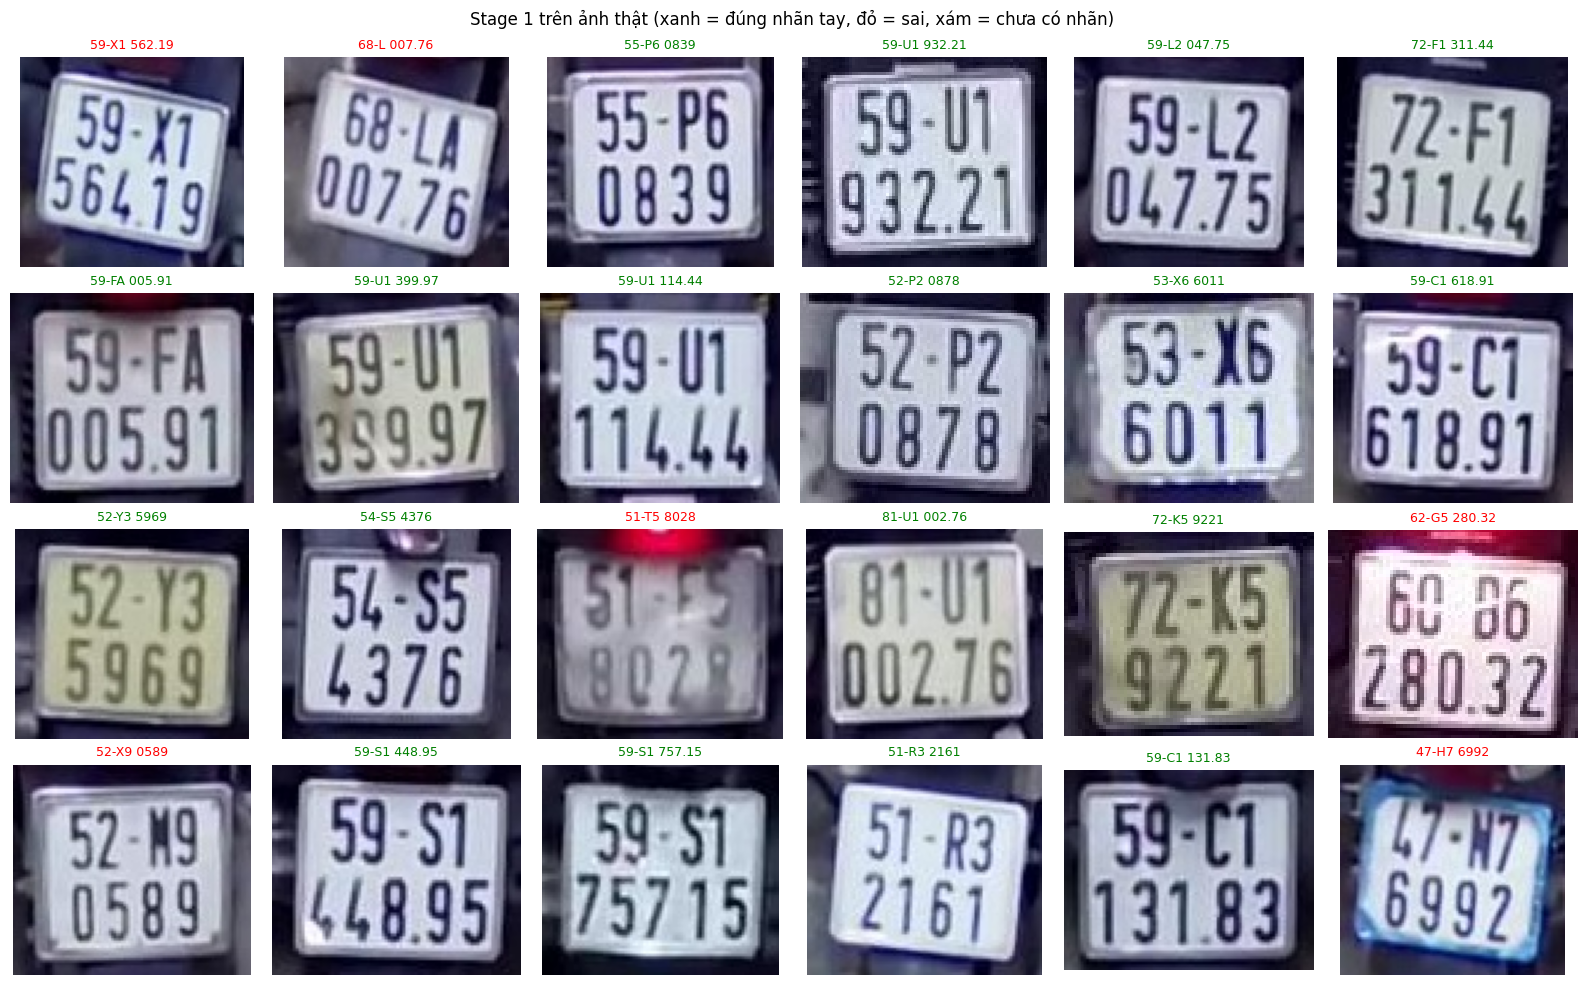

In [9]:
# =====================================================================
# CELL 7: NHÃN TAY -> CHIA THEO BIỂN SỐ -> ĐO STAGE 1 TRÊN ẢNH THẬT -> (tuỳ chọn) NHÃN GIẢ
# - Nhãn tay = seed nhúng sẵn (Cell 5B) + mọi CSV `real_labels*.csv` trong /kaggle/input (CSV của bạn ghi đè seed).
# - Chia train/eval theo CHÍNH BIỂN SỐ: cùng một xe xuất hiện ở nhiều nhóm ảnh -> chia theo nhóm vẫn rò rỉ.
# - Độ tin cậy CTC KHÔNG đáng tin ở model yếu (lần chạy đầu: sai nhiều nhưng conf 0.92-1.00) -> nhãn giả chỉ dùng khi
#   USE_PSEUDO=True và stage 1 đã đạt PSEUDO_GATE trên tập thật có nhãn tay.
# =====================================================================
import io


@torch.no_grad()
def predict_paths(model, paths, bs=128):
    model.eval(); outs = []
    for i in range(0, len(paths), bs):
        xs = np.concatenate([to_input(cv2.imread(p), 0.5) for p in paths[i:i + bs]])
        lg = model(torch.from_numpy(xs).to(DEVICE)).float().cpu().numpy()
        outs += [format_plate(*ctc_greedy(l)) for l in lg]
    return outs


human = {}


def add_labels(d):
    for fn, tx in zip(d["file"], d["text"]):
        tg = text_to_target(tx)
        if tg and (CROP_DIR / fn).exists():
            human[fn] = tg


add_labels(pd.read_csv(io.StringIO(SEED_LABELS_CSV)))
n_seed = len(human)
HARD = {}
for _csv in (HARD_LABELS_CSV, HARD2_LABELS_CSV):
    _h = pd.read_csv(io.StringIO(_csv))
    for fn, tx in zip(_h["file"], _h["text"]):
        tg = text_to_target(tx)
        if tg and (CROP_DIR / fn).exists():
            HARD[fn] = tg
TEST = {}
_t = pd.read_csv(io.StringIO(TEST_LABELS_CSV))
for fn, tx in zip(_t["file"], _t["text"]):
    tg = text_to_target(tx)
    if tg and (CROP_DIR / fn).exists():
        TEST[fn] = tg
T_items = [(str(CROP_DIR / f), t) for f, t in TEST.items()]
print(f"nhãn khó (train): {len(HARD)} | nhãn KIỂM TRA độc lập: {len(TEST)}")
for f in glob.glob("/kaggle/input/**/*real_labels*.csv", recursive=True) + glob.glob("./**/real_labels*.csv", recursive=True):
    if "template" not in f:
        add_labels(pd.read_csv(f)); print("đọc thêm nhãn tay:", f)
print(f"nhãn tay hợp lệ: {len(human)} (seed {n_seed})")

for f_, t_ in HARD.items():                       # nhãn khó chỉ để train: gắn vào sau khi chia eval
    human.setdefault(f_, t_)
human = {f: t for f, t in human.items() if f not in TEST and t not in set(TEST.values())}   # TEST tách hẳn (cả theo biển số)
H_df = pd.DataFrame([dict(file=f, target=t, path=str(CROP_DIR / f)) for f, t in human.items()])
plates = sorted(H_df.target.unique()); random.Random(SEED).shuffle(plates)
eval_plates = set(plates) if len(plates) < 60 else set(plates[:int(len(plates) * 0.3)])
H_df["is_eval"] = H_df.target.isin(eval_plates) & ~H_df.file.isin(HARD)
H_eval = [(r.path, r.target) for r in H_df.itertuples() if r.is_eval]
H_train = [(r.path, r.target) for r in H_df.itertuples() if not r.is_eval and r.target not in eval_plates]   # không để biển của eval lọt vào train
print(f"tập đánh giá thật: {len(H_eval)} ảnh ({len(eval_plates)} biển) | train nhãn tay: {len(H_train)} ảnh")
if len(H_eval) < 60:
    print("[i] Tập đánh giá nhỏ (<60) -> số đo dao động mạnh (±10 điểm %); dùng để PHÁT HIỆN LỖI hơn là so sánh sát nhau.")

S1_REAL = evaluate(model1, RealDS(H_eval, train=False)) if H_eval else None
if S1_REAL:
    print(f"\nSTAGE 1 trên ảnh THẬT (nhãn tay): exact={S1_REAL['exact']:.3f}  CER={S1_REAL['cer']:.3f}")
    print("nhầm lẫn ký tự (thật→đoán:số lần):", S1_REAL["confusions"])
    print("ví dụ sai (nhãn, dự đoán):", S1_REAL["wrong"][:6])

preds = predict_paths(model1, REAL["path"].tolist())
REAL["pred_raw"] = [p["raw"] for p in preds]; REAL["pred_text"] = [p["text"] for p in preds]
REAL["conf"] = [p["conf"] for p in preds]; REAL["valid"] = [p["valid"] for p in preds]
REAL["pred_target"] = [text_to_target(p["text"]) for p in preds]
REAL["human"] = REAL.file.map(human)

# file mẫu để bạn gán nhãn thêm: chỉ crop CHƯA có nhãn, sắp theo tên (conf không dùng để sắp vì không đáng tin)
REAL[REAL.human.isna()][["file", "pred_text", "conf"]].rename(columns={"pred_text": "text"}).sort_values("file") \
    .to_csv(OUT / "real_labels_template.csv", index=False)

P_items = []
PSEUDO_OK = bool(USE_PSEUDO and S1_REAL and S1_REAL["exact"] >= PSEUDO_GATE)
if USE_PSEUDO and not PSEUDO_OK:
    print(f"[i] Nhãn giả KHÔNG dùng: stage 1 chưa đạt {PSEUDO_GATE:.2f} exact trên tập thật có nhãn tay.")
if PSEUDO_OK:
    sel = REAL[REAL.human.isna() & REAL.valid & (REAL.conf >= PSEUDO_CONF) & REAL.pred_target.notna() & ~REAL.pred_target.isin(eval_plates)]
    P_items = [(r.path, r.pred_target) for r in sel.itertuples()]
print(f"nhãn giả dùng: {len(P_items)}")

# 24 ảnh thật: xanh = khớp nhãn tay, đỏ = KHÁC nhãn tay, xám = chưa có nhãn tay
fig, axs = plt.subplots(4, 6, figsize=(16, 10))
smp = REAL[REAL.human.notna()] if REAL.human.notna().sum() >= 24 else REAL
for ax, (_, r) in zip(axs.ravel(), smp.sample(min(24, len(smp)), random_state=5).iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(r["path"]), cv2.COLOR_BGR2RGB)); ax.axis("off")
    col = "gray" if pd.isna(r["human"]) else ("green" if text_to_target(r["pred_text"]) == r["human"] else "red")
    ax.set_title(f"{r.pred_text}", fontsize=9, color=col)
plt.suptitle("Stage 1 trên ảnh thật (xanh = đúng nhãn tay, đỏ = sai, xám = chưa có nhãn)"); plt.tight_layout()
plt.savefig(OUT / "figures" / "stage1_real_preds.png", dpi=100); plt.show()

In [10]:
# =====================================================================
# CELL 8: STAGE 2 - FINE-TUNE TRỘN (tổng hợp + nhãn giả + nhãn tay)
# =====================================================================
real_items = P_items + H_train * HUMAN_WEIGHT
final_model, stage_used = model1, "stage1"
model2 = None
if len(real_items) >= 50:
    target_n = SYN_TRAIN_N // 2
    rep = max(1, min(target_n // len(real_items), 40))
    mix = ConcatDataset([SynthDS(SYN_TRAIN_N // 2, seed=2000), RealDS(real_items * rep, train=True)])
    model2 = CRNN(); model2.load_state_dict(model1.state_dict())
    val_fn = (lambda m: evaluate(m, RealDS(H_eval, train=False))) if H_eval else (lambda m: evaluate(m, syn_val))
    model2, _ = fit(model2, mix, val_fn, EPOCHS_S2, LR_S2, "S2", deadline)
    torch.save(model2.state_dict(), OUT / "crnn_stage2.pt")
else:
    print(f"[!] Chỉ có {len(real_items)} mẫu thật (<50) -> bỏ stage 2, dùng stage 1.")

# ---- bảng so sánh ----
rep_rows = []
for tag, mdl in [("stage1", model1), ("stage2", model2)]:
    if mdl is None:
        continue
    r = dict(model=tag, synth_exact=round(evaluate(mdl, syn_val)["exact"], 4))
    if H_eval:
        e = evaluate(mdl, RealDS(H_eval, train=False)); r.update(real_exact=round(e["exact"], 4), real_cer=round(e["cer"], 4), real_n=e["n"])
        r["_wrong"] = e["wrong"][:6]; r["_conf"] = e["confusions"]
    rep_rows.append(r)
for r in rep_rows:
    print({k: v for k, v in r.items() if not k.startswith("_")})
    if "_wrong" in r:
        print("   sai (nhãn, dự đoán):", r["_wrong"]); print("   nhầm lẫn:", r["_conf"])

# ---- chọn model cuối ----
if model2 is not None:
    if H_eval:
        s1 = next(r for r in rep_rows if r["model"] == "stage1")["real_exact"]; s2 = next(r for r in rep_rows if r["model"] == "stage2")["real_exact"]
        final_model, stage_used = (model2, "stage2") if s2 >= s1 else (model1, "stage1")
        print(f"==> chọn {stage_used} theo exact-match trên tập thật có nhãn tay (stage1={s1}, stage2={s2})")
    else:
        final_model, stage_used = model2, "stage2"
        print("==> chọn stage2 mặc định, CHƯA được xác nhận bằng nhãn tay (có rủi ro tự củng cố lỗi của nhãn giả).")
REAL_EVAL_FINAL = evaluate(final_model, RealDS(H_eval, train=False)) if H_eval else None

/tmp/ipykernel_50/4254785052.py:119: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))


[S2] ep 01/20  loss=0.0369  val exact=1.0000 cer=0.0000  (102s)
[S2] ep 02/20  loss=0.0067  val exact=1.0000 cer=0.0000  (144s)
[S2] ep 03/20  loss=0.0049  val exact=1.0000 cer=0.0000  (105s)
[S2] ep 04/20  loss=0.0040  val exact=1.0000 cer=0.0000  (105s)
[S2] ep 05/20  loss=0.0035  val exact=1.0000 cer=0.0000  (104s)
[S2] ep 06/20  loss=0.0040  val exact=0.9808 cer=0.0020  (105s)
[S2] ep 07/20  loss=0.0034  val exact=1.0000 cer=0.0000  (106s)
[S2] ep 08/20  loss=0.0030  val exact=0.9808 cer=0.0020  (105s)
[S2] ep 09/20  loss=0.0045  val exact=1.0000 cer=0.0000  (106s)
[S2] ep 10/20  loss=0.0035  val exact=0.9808 cer=0.0020  (107s)
[S2] ep 11/20  loss=0.0027  val exact=1.0000 cer=0.0000  (107s)
[S2] ep 12/20  loss=0.0031  val exact=1.0000 cer=0.0000  (109s)
[S2] ep 13/20  loss=0.0025  val exact=1.0000 cer=0.0000  (106s)
[S2] ep 14/20  loss=0.0017  val exact=1.0000 cer=0.0000  (107s)
[S2] ep 15/20  loss=0.0018  val exact=1.0000 cer=0.0000  (106s)
[S2] ep 16/20  loss=0.0018  val exact=1.

In [11]:
# =====================================================================
# CELL 9: XUẤT ONNX + KIỂM CHỨNG TƯƠNG ĐƯƠNG + ĐO ĐỘ TRỄ + ĐÁNH GIÁ END-TO-END BẰNG plate_ocr.OnnxOCR
# =====================================================================
final_model.eval().cpu()
ONNX_PATH = OUT / "plate_ocr.onnx"
dummy = torch.zeros(1, 1, 32, 256)
kw = dict(input_names=["x"], output_names=["logits"], dynamic_axes={"x": {0: "b"}, "logits": {0: "b"}}, opset_version=17)
try:
    torch.onnx.export(final_model, dummy, str(ONNX_PATH), dynamo=False, **kw)
except TypeError:
    torch.onnx.export(final_model, dummy, str(ONNX_PATH), **kw)
print("ONNX:", ONNX_PATH, f"{ONNX_PATH.stat().st_size / 1e6:.2f} MB")

ocr = plate_ocr.OnnxOCR(ONNX_PATH, threads=4)
rng = np.random.default_rng(12345)
imgs = [synth_sample(rng) for _ in range(300)]
xb = np.concatenate([to_input(im, 0.5) for im, _, _ in imgs[:32]])
with torch.no_grad():
    d = np.abs(final_model(torch.from_numpy(xb)).numpy() - ocr.sess.run(None, {ocr.inp: xb})[0]).max()
print(f"|PyTorch - ONNX| max = {d:.2e}  ({'OK' if d < 1e-3 else 'LỆCH - kiểm tra export'})")

ex = sum(ocr(im, votes=1)["raw"] == tg for im, tg, _ in imgs) / len(imgs)
print(f"[ONNX end-to-end] synthetic exact (1 phiếu, 300 mẫu): {ex:.4f}")
if H_eval:
    for v in (1, 3):
        ok = sum(ocr(cv2.imread(p), votes=v)["raw"] == t for p, t in H_eval) / len(H_eval)
        print(f"[ONNX end-to-end] ẢNH THẬT có nhãn tay, bỏ phiếu {v}: exact={ok:.4f} trên {len(H_eval)} ảnh   <-- chỉ số đáng tin")
if T_items:
    print("\n===== TẬP KIỂM TRA ĐỘC LẬP (không dùng để train / chọn model) =====")
    for v in (1, 3):
        res = [ocr(cv2.imread(p), votes=v) for p, _ in T_items]
        okv = [r["raw"] == t for r, (_, t) in zip(res, T_items)]
        print(f"bỏ phiếu {v}: exact = {sum(okv)}/{len(okv)} = {np.mean(okv):.4f}")
    TEST_RES = dict(n=len(T_items), exact_votes3=float(np.mean(okv)), exact_votes1=float(np.mean([ocr(cv2.imread(p), votes=1)["raw"] == t for p, t in T_items])))
    for r, (p, t) in zip(res, T_items):
        if r["raw"] != t:
            print("  SAI:", Path(p).name, "| nhãn:", t, "| đoán:", r["raw"], f"| conf={r['conf']:.3f} valid={r['valid']} agree={r['agree']:.2f}")
    print("(n≈90 -> khoảng tin cậy 95% rộng cỡ ±3–6 điểm %; đây là ước lượng cho ảnh GreenParking, KHÔNG phải cho camera ESP32-CAM của bạn.)")
else:
    TEST_RES = None
ts = []
for im, _, _ in imgs[:5]:
    ocr(im)
for im, _, _ in imgs[:200]:
    t = time.perf_counter(); ocr(im); ts.append((time.perf_counter() - t) * 1000)   # 3 phiếu = 1 batch 3 ảnh
print(f"độ trễ OCR (CPU Kaggle, 4 luồng): median {np.median(ts):.1f} ms/biển  <- Pi 4 sẽ chậm hơn, hãy đo lại trên Pi")

/tmp/ipykernel_50/95987958.py:9: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(final_model, dummy, str(ONNX_PATH), dynamo=False, **kw)
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py:4571: UserWarning: Exporting a model to ONNX with a batch_size other than 1, with a variable length with GRU can cause an error when running the ONNX model with a different batch size. Make sure to save the model with a batch size of 1, or define the initial states (h0/c0) as inputs of the model. 
  return _generic_rnn(


ONNX: /kaggle/working/plate_ocr.onnx 5.99 MB
|PyTorch - ONNX| max = 1.25e-05  (OK)
[ONNX end-to-end] synthetic exact (1 phiếu, 300 mẫu): 0.9967
[ONNX end-to-end] ẢNH THẬT có nhãn tay, bỏ phiếu 1: exact=1.0000 trên 52 ảnh   <-- chỉ số đáng tin
[ONNX end-to-end] ẢNH THẬT có nhãn tay, bỏ phiếu 3: exact=1.0000 trên 52 ảnh   <-- chỉ số đáng tin

===== TẬP KIỂM TRA ĐỘC LẬP (không dùng để train / chọn model) =====
bỏ phiếu 1: exact = 87/88 = 0.9886
bỏ phiếu 3: exact = 87/88 = 0.9886
  SAI: 0159_00418_b_0.jpg | nhãn: 59N1|76654 | đoán: 59H1|76654 | conf=0.991 valid=True agree=0.67
(n≈90 -> khoảng tin cậy 95% rộng cỡ ±3–6 điểm %; đây là ước lượng cho ảnh GreenParking, KHÔNG phải cho camera ESP32-CAM của bạn.)
độ trễ OCR (CPU Kaggle, 4 luồng): median 13.4 ms/biển  <- Pi 4 sẽ chậm hơn, hãy đo lại trên Pi


In [12]:
# =====================================================================
# CELL 10: SCRIPT GHÉP DETECTOR + OCR CHO PI 4 + ĐÓNG GÓI
# =====================================================================
ALPR_PY = r'''"""alpr_pipeline.py - Raspberry Pi 4: YOLO26 (NCNN) phát hiện biển -> crop -> OCR ONNX.

Cài:   pip install ultralytics ncnn onnxruntime opencv-python-headless
Chạy:  python alpr_pipeline.py --det plate_ncnn_model --ocr plate_ocr.onnx --source ./anh_thu --csv ket_qua.csv
       python alpr_pipeline.py --det plate_ncnn_model --ocr plate_ocr.onnx --source http://<IP_ESP32_CAM>:81/stream
"""
import argparse, csv, time
from pathlib import Path
import cv2
from ultralytics import YOLO
from plate_ocr import OnnxOCR, CROP_MARGIN

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def crop(img, xyxy, margin=CROP_MARGIN):
    h, w = img.shape[:2]
    x1, y1, x2, y2 = xyxy
    mx, my = (x2 - x1) * margin, (y2 - y1) * margin
    return img[int(max(y1 - my, 0)):int(min(y2 + my, h)), int(max(x1 - mx, 0)):int(min(x2 + mx, w))]


def frames(source):
    p = Path(source)
    if p.is_dir() or p.suffix.lower() in IMG_EXTS:
        for f in (sorted(q for q in p.iterdir() if q.suffix.lower() in IMG_EXTS) if p.is_dir() else [p]):
            yield f.name, cv2.imread(str(f))
    else:
        cap = cv2.VideoCapture(int(source) if source.isdigit() else source); i = 0
        while cap.isOpened():
            ok, frm = cap.read()
            if not ok:
                break
            yield f"frame_{i:06d}", frm; i += 1
        cap.release()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--det", required=True); ap.add_argument("--ocr", required=True); ap.add_argument("--source", required=True)
    ap.add_argument("--imgsz", default="320,480"); ap.add_argument("--conf", type=float, default=0.35)
    ap.add_argument("--min-ocr-conf", type=float, default=0.6); ap.add_argument("--csv", default="")
    a = ap.parse_args()
    imgsz = [int(v) for v in a.imgsz.split(",")] if "," in a.imgsz else int(a.imgsz)
    det = YOLO(a.det, task="detect"); ocr = OnnxOCR(a.ocr)
    w = csv.writer(open(a.csv, "w", newline="", encoding="utf-8")) if a.csv else None
    if w:
        w.writerow(["source", "text", "det_conf", "ocr_conf", "valid"])
    for name, img in frames(a.source):
        if img is None:
            continue
        t = time.perf_counter()
        r = det.predict(img, imgsz=imgsz, conf=a.conf, device="cpu", verbose=False)[0]
        for k, b in enumerate(r.boxes.xyxy.cpu().numpy().tolist()):
            res = ocr(crop(img, b))
            sure = res["valid"] and res["conf"] >= a.min_ocr_conf and res.get("agree", 1.0) >= 0.99
            flag = "" if sure else "  [KHÔNG CHẮC - cần kiểm tra]"      # lưu ý: conf cao KHÔNG đảm bảo đúng (từng sai với conf 0.999)
            print(f"{name}: {res['text']}  det={float(r.boxes.conf[k]):.2f} ocr={res['conf']:.2f}{flag}")
            if w:
                w.writerow([name, res["text"], f"{float(r.boxes.conf[k]):.3f}", f"{res['conf']:.3f}", res["valid"]])
        if not len(r.boxes):
            print(f"{name}: không thấy biển")
        # TODO: bỏ phiếu nhiều khung hình liên tiếp của cùng một xe để tăng độ tin cậy (chưa làm).


if __name__ == "__main__":
    main()
'''
BUNDLE = OUT / "ocr_bundle"
if BUNDLE.exists():
    shutil.rmtree(BUNDLE)
BUNDLE.mkdir()
shutil.copy2(OUT / "plate_ocr.py", BUNDLE / "plate_ocr.py")
shutil.copy2(ONNX_PATH, BUNDLE / "plate_ocr.onnx")
(BUNDLE / "alpr_pipeline.py").write_text(ALPR_PY, encoding="utf-8")
shutil.copy2(OUT / "real_labels_template.csv", BUNDLE / "real_labels_template.csv")
for f in (OUT / "figures").glob("*.png"):
    shutil.copy2(f, BUNDLE / f.name)
torch.save(final_model.state_dict(), BUNDLE / "crnn_final.pt")
(BUNDLE / "model_info.json").write_text(json.dumps(dict(
    task="OCR biển số xe máy VN 2 dòng (CRNN+CTC)", model_used=stage_used, vocab=VOCAB, input="(1,1,32,256) float32, tiền xử lý = plate_ocr.make_line",
    params_M=round(n_par / 1e6, 2), human_labels=len(human), human_seed=n_seed, human_eval_n=len(H_eval), pseudo_labels=len(P_items), version="v2",
    real_eval_exact=(REAL_EVAL_FINAL or {}).get("exact"), real_eval_cer=(REAL_EVAL_FINAL or {}).get("cer"),
    note_eval="real_eval_* đã dùng để chọn epoch/stage -> lạc quan. Hãy dùng heldout_test_*.", heldout_test=TEST_RES,
    note="Chỉ số trên dữ liệu tổng hợp KHÔNG phản ánh độ chính xác thật. real_eval_* = null nghĩa là chưa có nhãn tay.",
    todo=["Sửa real_labels_template.csv để có tập đánh giá thật", "Biển 2 chữ seri / biển ô tô / biển màu khác", "Bỏ phiếu nhiều khung hình", "Đo độ trễ trên Pi 4"],
), indent=2, ensure_ascii=False))
zip_path = shutil.make_archive(str(OUT / "plate_ocr_bundle"), "zip", BUNDLE)
print("Đã đóng gói:", zip_path); print(sorted(p.name for p in BUNDLE.iterdir()))
print(f"Tổng thời gian: {(time.time() - T0) / 60:.1f} phút")

Đã đóng gói: /kaggle/working/plate_ocr_bundle.zip
['alpr_pipeline.py', 'crnn_final.pt', 'model_info.json', 'plate_ocr.onnx', 'plate_ocr.py', 'real_crops.png', 'real_labels_template.csv', 'stage1_real_preds.png', 'synthetic_samples.png']
Tổng thời gian: 78.9 phút


## Triển khai trên Pi 4 cùng detector

1. Giải nén `plate_ocr_bundle.zip` và `plate_detector_bundle.zip` (từ notebook detector) vào cùng một thư mục trên Pi.
2. `pip install ultralytics ncnn onnxruntime opencv-python-headless`
3. `python alpr_pipeline.py --det plate_ncnn_model --ocr plate_ocr.onnx --source ./anh_thu --csv ket_qua.csv`

**Việc cần làm tiếp (chưa làm trong notebook):**
- Sửa `real_labels_template.csv` → upload `real_labels.csv` → chạy lại để có số đo thật và dữ liệu thật cho fine-tune.
- Gom ảnh thật từ ESP32-CAM tại cổng (chất lượng JPEG/góc/ánh sáng khác GreenParking) và gán nhãn thêm.
- Bỏ phiếu nhiều khung hình, các loại biển chưa hỗ trợ, đo độ trễ thật trên Pi.